In [59]:
import pandas as pd

In [ ]:
def data_loud(path):
    df = pd.read_csv(
    path,
    keep_default_na=False,
    na_values=["?"]
    )
    return df
 

In [ ]:
df = load_data("C:/Users/A TO Z/projects/healthequity-agent/data/diabetic_data.csv")

In [61]:

df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [9]:
df.shape


(101766, 50)

In [10]:
df.columns.tolist()

['encounter_id',
 'patient_nbr',
 'race',
 'gender',
 'age',
 'weight',
 'admission_type_id',
 'discharge_disposition_id',
 'admission_source_id',
 'time_in_hospital',
 'payer_code',
 'medical_specialty',
 'num_lab_procedures',
 'num_procedures',
 'num_medications',
 'number_outpatient',
 'number_emergency',
 'number_inpatient',
 'diag_1',
 'diag_2',
 'diag_3',
 'number_diagnoses',
 'max_glu_serum',
 'A1Cresult',
 'metformin',
 'repaglinide',
 'nateglinide',
 'chlorpropamide',
 'glimepiride',
 'acetohexamide',
 'glipizide',
 'glyburide',
 'tolbutamide',
 'pioglitazone',
 'rosiglitazone',
 'acarbose',
 'miglitol',
 'troglitazone',
 'tolazamide',
 'examide',
 'citoglipton',
 'insulin',
 'glyburide-metformin',
 'glipizide-metformin',
 'glimepiride-pioglitazone',
 'metformin-rosiglitazone',
 'metformin-pioglitazone',
 'change',
 'diabetesMed',
 'readmitted']

In [11]:
df['patient_nbr'].nunique()

71518

In [12]:
df.info(
    
)

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

In [6]:
df.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

In [14]:
missing_pct = df.isna().mean() * 100
missing_pct[missing_pct > 0].sort_values(ascending=False).round(2)

weight               96.86
medical_specialty    49.08
payer_code           39.56
race                  2.23
diag_3                1.40
diag_2                0.35
diag_1                0.02
dtype: float64

In [15]:
df_work = df.drop(columns=["weight"]).copy()

print("Original:", df.shape)
print("Working copy:", df_work.shape)

Original: (101766, 50)
Working copy: (101766, 49)


In [16]:
print("Duplicate rows:", df_work.duplicated().sum())
print("Duplicate encounter IDs:", df_work["encounter_id"].duplicated().sum())

Duplicate rows: 0
Duplicate encounter IDs: 0


In [17]:
counts = df_work["readmitted"].value_counts(dropna=False)

pd.DataFrame({
    "count": counts,
    "percent": (counts / len(df_work) * 100).round(2)
})

,count,percent
readmitted,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16


In [19]:
visits_per_patient = df_work["patient_nbr"].value_counts()

print("Patients with multiple stays:", (visits_per_patient > 1).sum())
print("Maximum stays for one patient:", visits_per_patient.max())

Patients with multiple stays: 16773
Maximum stays for one patient: 40


In [20]:
print("Gender:")
print(df_work["gender"].value_counts(dropna=False))

print("\nRace:")
print(df_work["race"].value_counts(dropna=False))

Gender:
gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

Race:
race
Caucasian          76099
AfricanAmerican    19210
NaN                 2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64


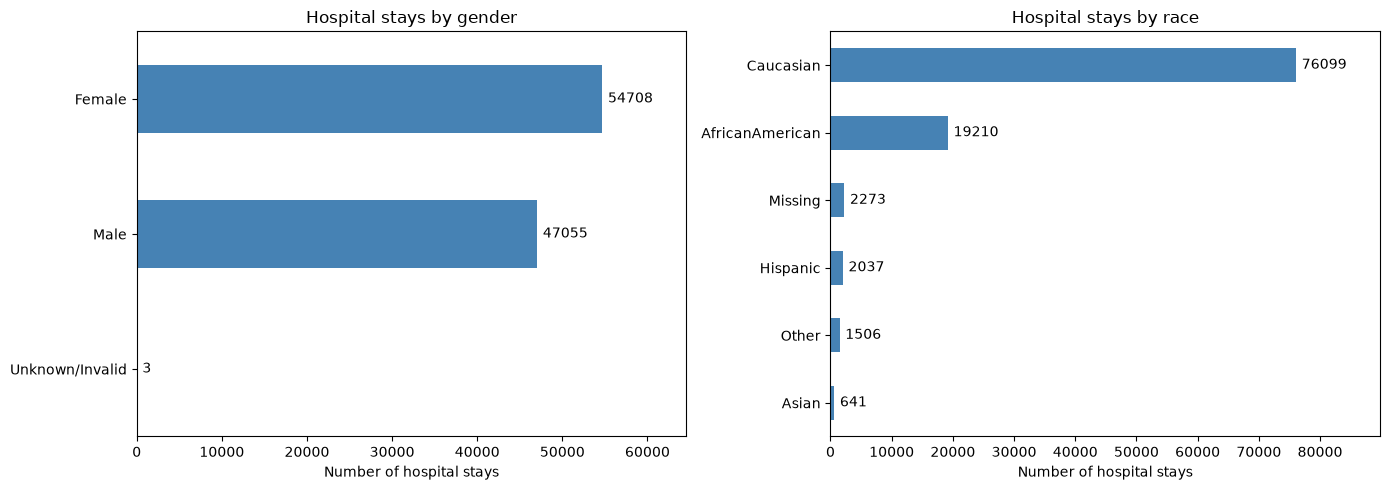

In [22]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, column in zip(axes, ["gender", "race"]):
    counts = df_work[column].fillna("Missing").value_counts()
    counts.plot.barh(ax=ax, color="#4682B4")

    ax.invert_yaxis()
    ax.set_title(f"Hospital stays by {column}")
    ax.set_xlabel("Number of hospital stays")
    ax.set_ylabel("")
    ax.bar_label(ax.containers[0], fmt="%.0f", padding=4)
    ax.set_xlim(0, counts.max() * 1.18)

plt.tight_layout()
plt.show()

In [23]:
numeric_cols = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

summary = df_work[numeric_cols].describe().T

summary["variance"] = df_work[numeric_cols].var()
summary["range"] = summary["max"] - summary["min"]
summary["IQR"] = summary["75%"] - summary["25%"]

summary.round(2)

,count,mean,std,min,25%,50%,75%,max,variance,range,IQR
time_in_hospital,101766.0,4.40,2.99,1.0,2.0,4.0,6.0,14.0,8.91,13.0,4.0
num_lab_procedures,101766.0,43.10,19.67,1.0,31.0,44.0,57.0,132.0,387.08,131.0,26.0
num_procedures,101766.0,1.34,1.71,0.0,0.0,1.0,2.0,6.0,2.91,6.0,2.0
num_medications,101766.0,16.02,8.13,1.0,10.0,15.0,20.0,81.0,66.06,80.0,10.0
number_outpatient,101766.0,0.37,1.27,0.0,0.0,0.0,0.0,42.0,1.61,42.0,0.0
number_emergency,101766.0,0.20,0.93,0.0,0.0,0.0,0.0,76.0,0.87,76.0,0.0
number_inpatient,101766.0,0.64,1.26,0.0,0.0,0.0,1.0,21.0,1.59,21.0,1.0
number_diagnoses,101766.0,7.42,1.93,1.0,6.0,8.0,9.0,16.0,3.74,15.0,3.0


In [58]:
df_work["target"] = [int(x == "<30") for x in df_work["readmitted"]]
df_work["target"].value_counts()


target
0    90409
1    11357
Name: count, dtype: int64

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

<Axes: xlabel='time_in_hospital', ylabel='Count'>

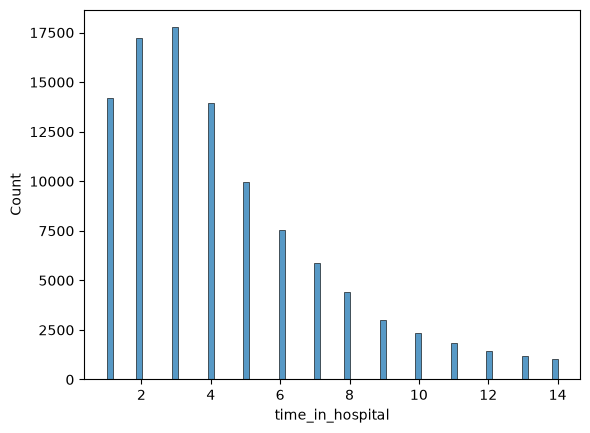

In [35]:
sns.histplot(data = df_work, x = "time_in_hospital")

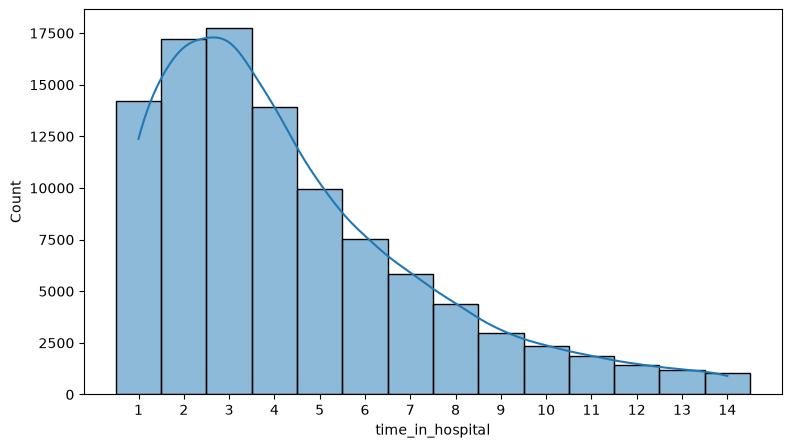

In [36]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_work,
    x="time_in_hospital",
    binwidth=1,
    binrange=(0.5, 14.5),
    kde=True,
    kde_kws={"bw_adjust": 2}
)

plt.xticks(range(1, 15))
plt.show()

Text(0.5, 0, 'time in hospital (day)')

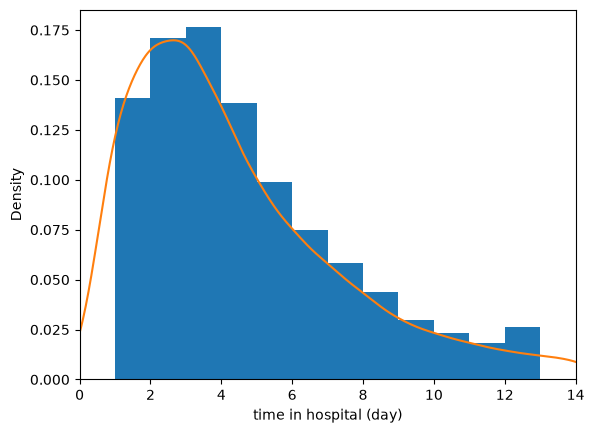

In [46]:
ax = df_work["time_in_hospital"].plot.hist(density = True,xlim = [0, 14],  bins = range(1, 14))

df_work["time_in_hospital"].plot.density(ax = ax, bw_method = 0.2)
ax.set_xlabel("time in hospital (day)")

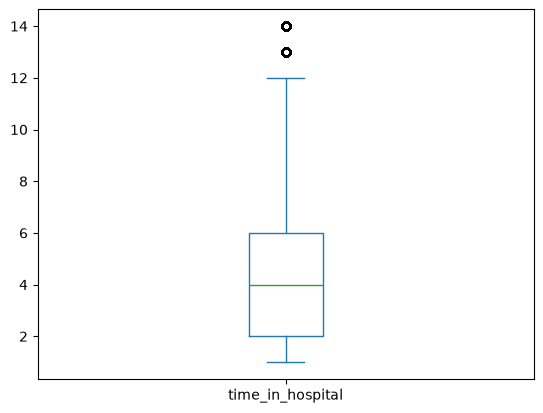

In [47]:
ax = df_work["time_in_hospital"].plot.box()

In [ ]:
df_work["time_in_hospital"]

In [62]:
y_true = [1, 0, 1, 0, 1, 0, 1, 0]
y_pred = [1, 0, 1, 0, 0, 0, 0, 0]

gender = ["Male", "Male", "Male", "Male",
          "Female", "Female", "Female", "Female"]

In [64]:
from fairlearn.metrics import MetricFrame
from sklearn.metrics import accuracy_score

result = MetricFrame(
    metrics=accuracy_score,
    y_true=y_true,
    y_pred=y_pred,
    sensitive_features=gender
)

print(result.overall)
print(result.by_group)

0.75
sensitive_feature_0
Female    0.5
Male      1.0
Name: accuracy_score, dtype: float64
